In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

In [3]:
data = pd.read_csv("ss_air_temp_vs_time.csv")

Saved ss_heater_T_vs_t.pdf and .png


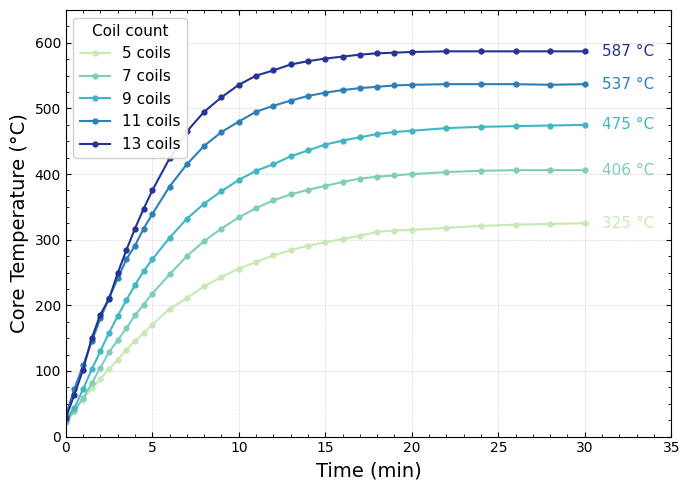

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

# --- Load data ---
df = pd.read_csv("ss_air_temp_vs_time.csv")

coil_labels = {
    "Temp_5coils_C":  ("5 coils",  "#c7e9b4"),
    "Temp_7coils_C":  ("7 coils",  "#7fcdbb"),
    "Temp_9coils_C":  ("9 coils",  "#41b6c4"),
    "Temp_11coils_C": ("11 coils", "#2c7fb8"),
    "Temp_13coils_C": ("13 coils", "#253494"),
}

fig, ax = plt.subplots(figsize=(7, 5))

for col, (label, color) in coil_labels.items():
    t = df["Time_min"]
    T = df[col]
    ax.plot(t, T, marker="o", markersize=3.5, linewidth=1.5,
            color=color, label=label)
    # Annotate steady-state value at t=30
    T_ss = T.iloc[-1]
    ax.annotate(f"{T_ss:.0f} °C",
                xy=(30, T_ss), xytext=(31, T_ss),
                fontsize=11, color=color, va="center")

ax.set_xlabel("Time (min)", fontsize=14)
ax.set_ylabel("Core Temperature (°C)", fontsize=14)
ax.set_xlim(0, 35)
ax.set_ylim(0, 650)
ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(25))
ax.tick_params(which="both", direction="in", top=True, right=True)
ax.legend(title="Coil count", fontsize=11, title_fontsize=11,
          loc="upper left", framealpha=0.9)
ax.grid(True, which="major", linestyle="--", linewidth=0.5, alpha=0.5)

plt.tight_layout()
plt.savefig("ss_heater_T_vs_t.pdf", dpi=300, bbox_inches="tight")
plt.savefig("ss_heater_T_vs_t.png", dpi=300, bbox_inches="tight")
print("Saved ss_heater_T_vs_t.pdf and .png")
plt.show()